In [1]:
import geopandas as gpd
import pyogrio
import rasterio
from rasterio import features
from rasterio.windows import Window, transform as window_transform
import numpy as np
import subprocess
import os
import gc
import resource


# Peak resident memory of this process, in MiB (ru_maxrss is KiB on Linux).
# Kaggle OOM-kills the kernel without a Python traceback, so log this after
# every state to see which one pushes the run over the limit.
def peak_rss_mib():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024


def pixel_window(bounds, transform, shape):
    """Integer pixel window covering `bounds`, clamped to the raster shape."""
    left, bottom, right, top = bounds
    inv = ~transform
    col_a, row_a = inv * (left, top)
    col_b, row_b = inv * (right, bottom)

    col_0 = max(0, min(int(np.floor(min(col_a, col_b))), shape[1] - 1))
    row_0 = max(0, min(int(np.floor(min(row_a, row_b))), shape[0] - 1))
    col_1 = max(0, min(int(np.ceil(max(col_a, col_b))), shape[1]))
    row_1 = max(0, min(int(np.ceil(max(row_a, row_b))), shape[0]))

    return Window(col_0, row_0, col_1 - col_0, row_1 - row_0)


# 1. Configuration & Paths
nwi_folder = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/"
master_raster_path = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff"
temp_mask_raster = "/kaggle/working/temp_wetland_mask.tif"
output_distance_raster = "/kaggle/working/wetland_distance.tiff"

# Polygons read and rasterized per step. Peak RAM scales with this, not with the
# size of a state: burning one IN-sized state in a single call needed ~7 GiB,
# while 20k polygons at a time needs well under 1 GiB.
CHUNK_SIZE = 20_000

state_files = [
    "IN_geopackage_wetlands.gpkg",
    "OH_geopackage_wetlands.gpkg",
    "MI_geopackage_wetlands.gpkg",
    "KY_geopackage_wetlands.gpkg",
    "PA_geopackage_wetlands.gpkg",
    "WV_geopackage_wetlands.gpkg",
]


# 2. Extract Master Grid Metadata & EXACT CRS
with rasterio.open(master_raster_path) as src:
    master_meta      = src.meta.copy()
    master_transform = src.transform
    master_shape     = src.shape  # (44027, 45094)
    master_crs       = src.crs    # Use the EXACT CRS from the master raster!

print(f"Master Grid loaded. Shape: {master_shape}")

mask_meta = master_meta.copy()
mask_meta.update(
    dtype=rasterio.uint8,
    nodata=0,
    count=1,
    compress="lzw",
    tiled=True,       # window writes stay cheap on a tiled GeoTIFF
    blockxsize=512,
    blockysize=512,
)


# 3. Burn every state into one shared mask, in chunks, window by window.
# No full-extent array is ever held in RAM: each chunk is rasterized into just
# its own bounding window and written back, preserving pixels burned earlier.
# "w+" (not "w") because every chunk reads its window back before overwriting it.
with rasterio.open(temp_mask_raster, "w+", **mask_meta) as dest:

    for file in state_files:

        file_path = os.path.join(nwi_folder, file)

        if not os.path.exists(file_path):
            print(f"Skipping {file} (not found)...")
            continue

        # Extract state prefix (e.g., "IN") to target the "<ST>_Wetlands" layer
        state_abbr   = file.split("_")[0]
        target_layer = f"{state_abbr}_Wetlands"

        # Fallback check in case a state names its layer slightly differently
        available_layers = [lyr[0] for lyr in pyogrio.list_layers(file_path)]

        if target_layer not in available_layers:
            # Pick the layer that ends with '_Wetlands'
            matches      = [lyr for lyr in available_layers if lyr.endswith("_Wetlands")]
            target_layer = matches[0] if matches else available_layers[0]

        print(f"Processing {file} (Layer: {target_layer})...")

        burned = 0
        chunks = 0
        offset = 0

        while True:

            # Palustrine wetlands only. The WHERE clause is applied before
            # paging, so skip_features/max_features walk the filtered set with
            # no gaps and no duplicates.
            gdf = gpd.read_file(
                file_path,
                layer=target_layer,
                engine="pyogrio",
                where="ATTRIBUTE LIKE 'P%' AND ATTRIBUTE NOT LIKE 'PUB%' AND ATTRIBUTE NOT LIKE 'PAB%'",
                columns=[],  # Only load geometries, skip attribute columns to save RAM
                skip_features=offset,
                max_features=CHUNK_SIZE,
            )

            if len(gdf) == 0:
                break

            offset += CHUNK_SIZE
            chunks += 1

            # Drop null geometries so total_bounds cannot come back as NaN
            gdf = gdf[gdf.geometry.notna()]

            if gdf.empty:
                del gdf
                gc.collect()
                continue

            # Reproject to match the exact master raster CRS (AEA WGS84)
            if gdf.crs != master_crs:
                gdf = gdf.to_crs(master_crs)

            # Burn only into this chunk's window, keeping what is already there
            win = pixel_window(gdf.total_bounds, master_transform, master_shape)

            if win.width > 0 and win.height > 0:

                tile = dest.read(1, window=win)

                features.rasterize(
                    shapes=((geom, 1) for geom in gdf.geometry if geom is not None),
                    out=tile,
                    transform=window_transform(win, master_transform),
                    merge_alg=rasterio.enums.MergeAlg.replace,
                    dtype=np.uint8,
                    all_touched=True
                )

                dest.write(tile, 1, window=win)
                del tile

            burned += len(gdf)
            del gdf
            gc.collect()

        print(f"  -> Burned {burned} polygons in {chunks} chunks | "
              f"peak RAM {peak_rss_mib():.0f} MiB")

print(f"Mask written: {temp_mask_raster} "
      f"({os.path.getsize(temp_mask_raster) / 2**20:.0f} MiB on disk)")
print(f"Peak RAM after mask write: {peak_rss_mib():.0f} MiB")


# 4. Calculate Euclidean Distance Out-of-Core via GDAL
print("Calculating continuous distance in meters using gdal_proximity...")

# -values 1:      measure distance to pixels with value 1 (wetlands)
# -distunits GEO: automatically multiplies pixel distance by 30m (georeferenced units)
# -ot Float32:    keeps output in 32-bit float instead of 64-bit float
cmd = [
    "gdal_proximity.py",
    temp_mask_raster,
    output_distance_raster,
    "-values", "1",
    "-distunits", "GEO",
    "-ot", "Float32",
    "-co", "COMPRESS=LZW",
    "-co", "BIGTIFF=YES",
]

subprocess.run(cmd, check=True)
print(f"Peak RAM after gdal_proximity: {peak_rss_mib():.0f} MiB")


# 5. Mask out pixels outside the 6-state cutline using the master NLCD raster
print("Applying 6-state cutline mask from master NLCD raster...")

DST_NODATA = -9999.0

with rasterio.open(master_raster_path) as master_src, \
     rasterio.open(output_distance_raster, "r+") as dist_dst:

    master_nodata = master_src.nodata  # 250 in Annual NLCD
    dist_dst.nodata = DST_NODATA

    # Stream in 2048-row strips so RAM stays under ~400 MiB
    step = 2048
    for row_off in range(0, master_src.height, step):
        h = min(step, master_src.height - row_off)
        win = Window(0, row_off, master_src.width, h)

        master_chunk = master_src.read(1, window=win)
        dist_chunk = dist_dst.read(1, window=win)

        # Anywhere NLCD is nodata (outside the 6 states) or Open Water (class 11, optional),
        # set wetland_distance to nodata (-9999.0)
        dist_chunk[master_chunk == master_nodata] = DST_NODATA
        dist_dst.write(dist_chunk, 1, window=win)

print("wetland_distance.tiff is now clipped to the exact 6-state boundary.")

# Clean up temporary mask file
os.remove(temp_mask_raster)

print(f"Done! Saved aligned distance raster to {output_distance_raster}")


Master Grid loaded. Shape: (44029, 45095)
Processing IN_geopackage_wetlands.gpkg (Layer: IN_Wetlands)...
  -> Burned 194514 polygons in 10 chunks | peak RAM 1250 MiB
Processing OH_geopackage_wetlands.gpkg (Layer: OH_Wetlands)...
  -> Burned 169215 polygons in 9 chunks | peak RAM 3235 MiB
Processing MI_geopackage_wetlands.gpkg (Layer: MI_Wetlands)...
  -> Burned 815978 polygons in 41 chunks | peak RAM 3235 MiB
Processing KY_geopackage_wetlands.gpkg (Layer: KY_Wetlands)...
  -> Burned 68952 polygons in 4 chunks | peak RAM 3235 MiB
Processing PA_geopackage_wetlands.gpkg (Layer: PA_Wetlands)...
  -> Burned 144613 polygons in 8 chunks | peak RAM 3235 MiB
Processing WV_geopackage_wetlands.gpkg (Layer: WV_Wetlands)...
  -> Burned 51779 polygons in 3 chunks | peak RAM 3922 MiB
Mask written: /kaggle/working/temp_wetland_mask.tif (20 MiB on disk)
Peak RAM after mask write: 3922 MiB
Calculating continuous distance in meters using gdal_proximity...
0...10...20...30...40...50...60...70...80...90...

45095 x 44029 px @ 30 m | CRS EPSG:5070 | nodata -9999.0
distance (m)  min 0 | p50 587 | p90 10549 | p95 27661 | p99 53859 | max 93920
overview pixels within 1 km of a wetland: 65.2%


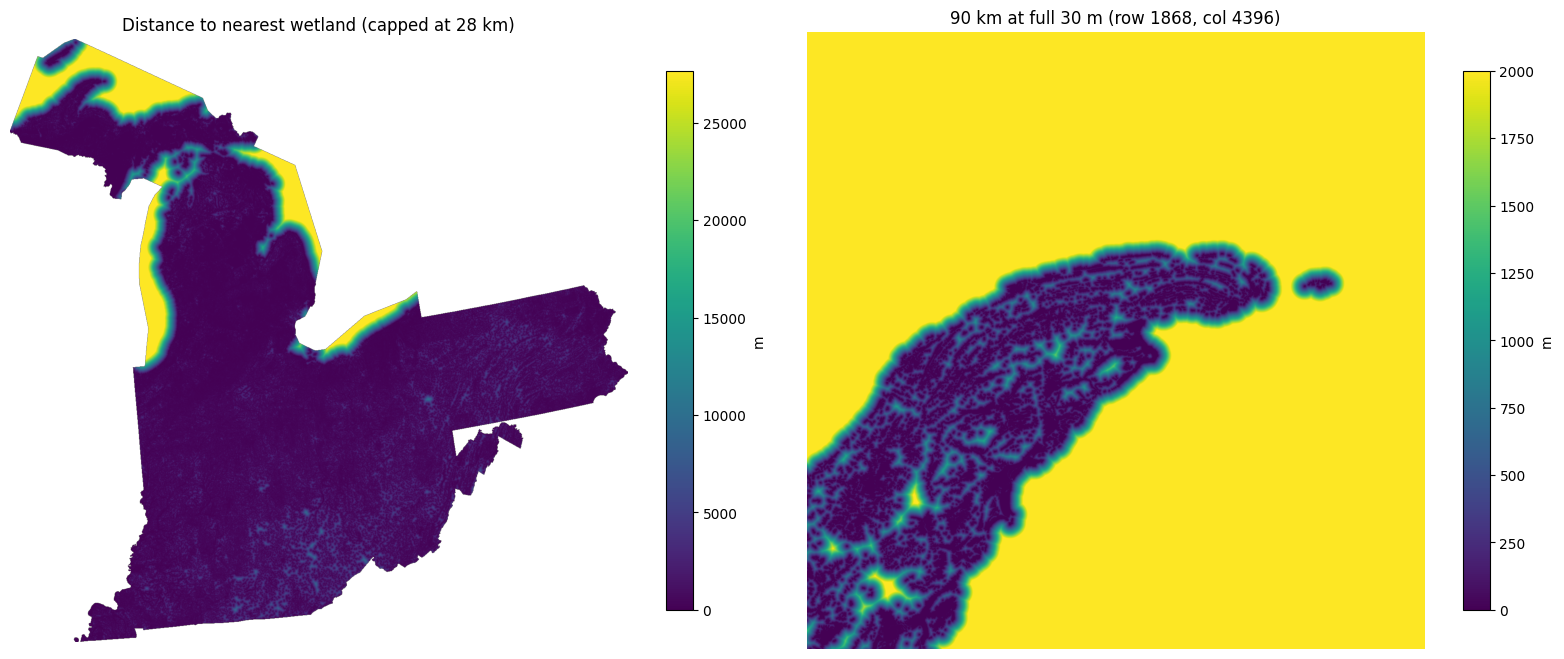

In [2]:
from rasterio.enums import Resampling
from rasterio.windows import Window
import matplotlib.pyplot as plt
import numpy as np
import rasterio


path = '/kaggle/working/wetland_distance.tiff'

with rasterio.open(path) as src:
    print(f"{src.width} x {src.height} px @ {abs(src.transform.a):.0f} m | "
          f"CRS {src.crs} | nodata {src.nodata}")

    # Overview. At this size one plotted pixel averages ~57x57 source pixels
    # (~1.7 km), so individual wetlands cannot survive this view.
    max_size = 1500
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

    values = image.filled(np.nan).astype('float64')
    valid = values[np.isfinite(values)]
    cap = max(float(np.percentile(valid, 95)), 1000.0)
    print("distance (m)  min {:.0f} | p50 {:.0f} | p90 {:.0f} | p95 {:.0f} | "
          "p99 {:.0f} | max {:.0f}".format(
              valid.min(), *np.percentile(valid, [50, 90, 95, 99]), valid.max()))
    print(f"overview pixels within 1 km of a wetland: {(valid < 1000).mean():.1%}")

    # Full-resolution 90 km look at the wetland-densest part of the overview.
    row, col = np.unravel_index(np.nanargmin(values), values.shape)
    src_row = int(row * src.height / height)
    src_col = int(col * src.width / width)
    half = 1500  # 1500 px * 30 m = 45 km
    row_off = min(max(0, src_row - half), max(0, src.height - 2 * half))
    col_off = min(max(0, src_col - half), max(0, src.width - 2 * half))

    crop = src.read(1, window=Window(col_off, row_off, 2 * half, 2 * half))


fig, (full, zoom) = plt.subplots(1, 2, figsize=(16, 8))

# Capped near the 95th percentile. Left uncapped, the few-hundred-km values
# in the empty corners become vmax and every real distance collapses to purple.
im = full.imshow(image, cmap='viridis', vmax=cap)
full.set_title(f'Distance to nearest wetland (capped at {cap / 1000:.0f} km)')
full.axis('off')
fig.colorbar(im, ax=full, shrink=0.7, label='m')

im = zoom.imshow(crop, cmap='viridis', vmax=2000)
zoom.set_title(f'90 km at full 30 m (row {row_off}, col {col_off})')
zoom.axis('off')
fig.colorbar(im, ax=zoom, shrink=0.7, label='m')

plt.tight_layout()
plt.show()
